# Selenium Assignment

In [1]:
import time
import pandas as pd
from selenium import webdriver
from selenium.webdriver.common.by import By
from selenium.webdriver.common.keys import Keys
from selenium.webdriver.common.action_chains import ActionChains
from selenium.webdriver.support.ui import WebDriverWait, Select
from selenium.webdriver.support import expected_conditions as EC
from IPython.display import Image

In [2]:
driver = webdriver.Edge()

wait = WebDriverWait(driver, 10)

print(driver.capabilities["browserName"], driver.capabilities["browserVersion"])

MicrosoftEdge 155.0.4283.45


In [3]:
# A1
driver.get('https://www.selenium.dev/selenium/web/web-form.html')
print(f'Titel: {driver.title}')
driver.get(' https://books.toscrape.com/')
print(f'Titel: {driver.title}')
driver.back()
print(f'Titel: {driver.title}')

Titel: Web form
Titel: All products | Books to Scrape - Sandbox
Titel: Web form


In [4]:
# A2
by_name = driver.find_element(By.NAME, 'my-password')
print(f'Type: {by_name.get_attribute('type')}')

Type: password


In [5]:
by_class = driver.find_elements(By.CLASS_NAME, 'input')
print(f'Count <input> elements: {len(by_class)}')

Count <input> elements: 0


In [6]:
by_css = driver.find_element(By.CSS_SELECTOR, "input[name='my-readonly']")
print(f'The value of the read-only field: {repr(by_css.get_attribute('value'))}')

The value of the read-only field: 'Readonly input'


In [7]:
by_link_text = driver.find_element(By.LINK_TEXT,'Return to index')
print(f'Href: {repr(by_link_text.get_attribute('href'))}')

Href: 'https://www.selenium.dev/selenium/web/index.html'


In [8]:
by_xpath = driver.find_element(By.XPATH, "//button[text()='Submit']")
print(f"XPATH: {by_xpath.tag_name}")

XPATH: button


In [9]:
# A3
text = driver.find_element(By.NAME, 'my-text')
text.clear()
text.send_keys('Mohammad Maher Metwally')
print(f'Check text value: {text.get_attribute('value')}')

Check text value: Mohammad Maher Metwally


In [10]:
textarea = driver.find_element(By.NAME, 'my-textarea')
textarea.clear()
textarea.send_keys('Hello,\nworld')
print(f'Check textarea value: {repr(textarea.get_attribute('value'))}')

Check textarea value: 'Hello,\nworld'


In [11]:
dropdown = Select(driver.find_element(By.NAME, 'my-select'))
print(f'Check dropdown value before select: {dropdown.first_selected_option.text}')
dropdown.select_by_index('3')
print(f'Check dropdown value after select: {dropdown.first_selected_option.text}')

Check dropdown value before select: Open this select menu
Check dropdown value after select: Three


In [12]:
checkbox1 = driver.find_element(By.ID, 'my-check-1')
checkbox1.click()
print(f'Checkbox 1 Checked: {checkbox1.is_selected()}')

Checkbox 1 Checked: False


In [13]:
checkbox2 = driver.find_element(By.ID, 'my-check-2')
checkbox2.click()
print(f'Checkbox 2 Checked: {checkbox2.is_selected()}')

Checkbox 2 Checked: True


In [14]:
radio2 = driver.find_element(By.ID, 'my-radio-2')
radio2.click()
print(f'Radio 2 Checked: {radio2.is_selected()}')

Radio 2 Checked: True


In [15]:
driver.find_element(By.XPATH, "//button[text()='Submit']").click()
finished = wait.until(EC.visibility_of_element_located((By.ID, 'message')))
print('Submit Message', finished.text)

Submit Message Received!


In [16]:
# A4
driver.get('https://the-internet.herokuapp.com/dynamic_controls')

remove = driver.find_element(By.XPATH, '//button[text()="Remove"]')
remove.click()
after_remove = wait.until(EC.visibility_of_element_located((By.ID, 'message')))
print('Remove Message:', after_remove.text)

enable = driver.find_element(By.XPATH, '//button[text()="Enable"]')
enable.click()
after_enable = wait.until(EC.visibility_of_element_located((By.ID, 'message')))
print('Enable Message:', after_enable.text)

Remove Message: It's gone!
Enable Message: It's enabled!


In [17]:
driver.get('https://the-internet.herokuapp.com/javascript_alerts')

confirm = driver.find_element(By.XPATH, '//button[text()="Click for JS Confirm"]')
confirm.click()
alert = wait.until(EC.alert_is_present())
alert.accept()
result = driver.find_element(By.ID, "result").text
print(result)

You clicked: Ok


In [18]:
# A6
driver.get('https://the-internet.herokuapp.com/iframe')
driver.switch_to.frame("mce_0_ifr")
print('Editor text:', driver.find_element(By.ID, "tinymce").text)

driver.switch_to.parent_frame()
h3 = driver.find_element(By.TAG_NAME, 'h3')
print('Heading of <h3>:', h3.text)

Editor text: 
Heading of <h3>: An iFrame containing the TinyMCE WYSIWYG Editor


In [19]:
# A7
driver.get("https://the-internet.herokuapp.com/hovers")
figures = driver.find_elements(By.CSS_SELECTOR, "div.figure")

for fig in figures:
    ActionChains(driver).move_to_element(fig).perform()
    caption = fig.find_element(By.CSS_SELECTOR, "div.figcaption h5")
    wait.until(EC.visibility_of(caption))
    print(caption.text)

name: user1
name: user2
name: user3


In [20]:
# A8. Tabs
original_tab = driver.current_window_handle

driver.switch_to.new_window("tab")
driver.get("https://books.toscrape.com/")
print("New tab title:", driver.title)

driver.close()                               # close the new tab
driver.switch_to.window(original_tab)        # go back to the first tab
print("Back on original tab:", driver.title)

New tab title: All products | Books to Scrape - Sandbox
Back on original tab: The Internet


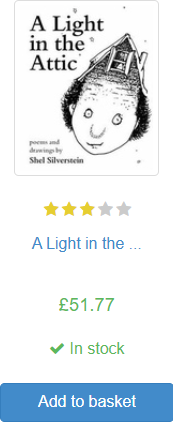

In [ ]:
# A9. JavaScript and screenshot
driver.get("https://books.toscrape.com/")
driver.execute_script("window.scrollTo(0, document.body.scrollHeight);")

first_book = driver.find_element(By.CSS_SELECTOR, "article.product_pod")
first_book.screenshot("data/first_book.png")
display(Image("first_book.png"))

In [22]:
# B1. One book
RATING_MAP = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

driver.get("https://books.toscrape.com/")
book = driver.find_element(By.CSS_SELECTOR, "article.product_pod")

# the visible text is cut with "...", the full title is in the title attribute
title = book.find_element(By.CSS_SELECTOR, "h3 a").get_attribute("title")
price = book.find_element(By.CSS_SELECTOR, "p.price_color").text
rating_word = book.find_element(By.CSS_SELECTOR, "p.star-rating").get_attribute("class").split()[-1]
availability = book.find_element(By.CSS_SELECTOR, "p.availability").text.strip()

print("Title:       ", title)
print("Price:       ", price)
print("Rating:      ", RATING_MAP[rating_word])
print("Availability:", availability)


Title:        A Light in the Attic
Price:        £51.77
Rating:       3
Availability: In stock


In [23]:
# B2. One page
def scrape_page(driver):
    """Return a list of dicts (title, price, rating, availability, link), one per book on the open page."""
    books = []
    for book in driver.find_elements(By.CSS_SELECTOR, "article.product_pod"):
        link_el = book.find_element(By.CSS_SELECTOR, "h3 a")
        rating_word = book.find_element(By.CSS_SELECTOR, "p.star-rating").get_attribute("class").split()[-1]
        books.append({
            "title": link_el.get_attribute("title"),
            "price": book.find_element(By.CSS_SELECTOR, "p.price_color").text,
            "rating": RATING_MAP[rating_word],
            "availability": book.find_element(By.CSS_SELECTOR, "p.availability").text.strip(),
            "link": link_el.get_attribute("href"),
        })
    return books


driver.get("https://books.toscrape.com/")
page_books = scrape_page(driver)
print(len(page_books), "books on the first page")
print(page_books[0])

20 books on the first page
{'title': 'A Light in the Attic', 'price': '£51.77', 'rating': 3, 'availability': 'In stock', 'link': 'https://books.toscrape.com/catalogue/a-light-in-the-attic_1000/index.html'}


In [24]:
# B3. Many pages (first 5)
all_books = []
driver.get("https://books.toscrape.com/")

for page in range(1, 6):
    all_books.extend(scrape_page(driver))
    print(f"Page {page} scraped, total so far: {len(all_books)}")

    if page < 5:
        driver.find_element(By.CSS_SELECTOR, "li.next a").click()
        time.sleep(1)  # wait 1 second between pages

driver.quit()

Page 1 scraped, total so far: 20
Page 2 scraped, total so far: 40
Page 3 scraped, total so far: 60
Page 4 scraped, total so far: 80
Page 5 scraped, total so far: 100


In [25]:
# B4. Clean
df = pd.DataFrame(all_books)

# "£51.77" -> 51.77
df["price"] = df["price"].str.replace(r"[^\d.]", "", regex=True).astype(float)

df["in_stock"] = df["availability"].str.contains("In stock", case=False)

# cheap: < 20, medium: 20 to < 40, expensive: >= 40
df["price_level"] = pd.cut(
    df["price"],
    bins=[float("-inf"), 20, 40, float("inf")],
    labels=["cheap", "medium", "expensive"],
    right=False,
)

df.head()

,title,price,rating,availability,link,in_stock,price_level
0,A Light in the Attic,51.77,3,In stock,https://books.toscrape.com/catalogue/a-light-i...,True,expensive
1,Tipping the Velvet,53.74,1,In stock,https://books.toscrape.com/catalogue/tipping-t...,True,expensive
2,Soumission,50.10,1,In stock,https://books.toscrape.com/catalogue/soumissio...,True,expensive
3,Sharp Objects,47.82,4,In stock,https://books.toscrape.com/catalogue/sharp-obj...,True,expensive
4,Sapiens: A Brief History of Humankind,54.23,5,In stock,https://books.toscrape.com/catalogue/sapiens-a...,True,expensive


In [ ]:
# B5. Save
df.to_csv("data/books.csv", index=False, encoding="utf-8")
print("Saved", len(df), "rows to books.csv")

Saved 100 rows to books.csv


In [27]:
# B6. Questions
# 1. Average, lowest and highest prices
print("Average price: £%.2f" % df["price"].mean())
print("Lowest price:  £%.2f" % df["price"].min())
print("Highest price: £%.2f" % df["price"].max())

# B6.2 Books per rating
print(df["rating"].value_counts().sort_index())

# B6.3 Rating >= 4 and price < £20
df[(df["rating"] >= 4) & (df["price"] < 20)][["title", "price", "rating"]]

Average price: £34.56
Lowest price:  £10.16
Highest price: £58.11
rating
1    22
2    19
3    22
4    18
5    19
Name: count, dtype: int64


,title,price,rating
12,Set Me Free,17.46,5
30,The Four Agreements: A Practical Guide to Pers...,17.66,5
34,Sophie's World,15.94,5
47,Untitled Collection: Sabbath Poems 2014,14.27,4
53,This One Summer,19.49,4
54,Thirst,17.27,5
80,"Princess Jellyfish 2-in-1 Omnibus, Vol. 01 (Pr...",13.61,5
81,Princess Between Worlds (Wide-Awake Princess #5),13.34,5
85,"Outcast, Vol. 1: A Darkness Surrounds Him (Out...",15.44,4
92,Mama Tried: Traditional Italian Cooking for th...,14.02,4


In [28]:
# Bonus 1. Detail pages (3 cheapest books)
driver = webdriver.Edge()          # the old driver was closed in B3
wait = WebDriverWait(driver, 10)
driver.get("https://books.toscrape.com/")
main_tab = driver.current_window_handle

for _, row in df.nsmallest(3, "price").iterrows():
    driver.switch_to.new_window("tab")
    driver.get(row["link"])
    upc = wait.until(
        EC.presence_of_element_located((By.XPATH, "//th[text()='UPC']/following-sibling::td"))
    ).text
    print(f"{row['title']} (£{row['price']}): UPC = {upc}")
    driver.close()
    driver.switch_to.window(main_tab)

Patience (£10.16): UPC = 9429b4d59c537af5
In Her Wake (£12.84): UPC = 23356462d1320d61
Princess Between Worlds (Wide-Awake Princess #5) (£13.34): UPC = 0e691eda369f4e09


In [29]:
# Bonus 2. A whole category (Mystery)
driver.get("https://books.toscrape.com/")
wait.until(EC.element_to_be_clickable((By.LINK_TEXT, "Mystery"))).click()

mystery_books = []
while True:
    wait.until(EC.presence_of_all_elements_located((By.CSS_SELECTOR, "article.product_pod")))
    mystery_books.extend(scrape_page(driver))

    next_buttons = driver.find_elements(By.CSS_SELECTOR, "li.next a")
    if not next_buttons:             # no Next button = last page
        break
    old_page_element = driver.find_element(By.CSS_SELECTOR, "article.product_pod")
    next_buttons[0].click()
    wait.until(EC.staleness_of(old_page_element))   # wait for the next page to load

print("Number of Mystery books:", len(mystery_books))
driver.quit()

Number of Mystery books: 32
